# 🤼 Kabaddi Matches EDA - Independent Visual Notebook

A clean, modular notebook designed to extract insights and generate visual charts answering the key Kabaddi tactical questions.


### Step 1: Load Data Files

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

def find_file(name):
    for path in [name, f"/content/{name}", f"data/cleaned/{name}", f"data/raw/{name}", f"cleaned_{name}", f"/content/cleaned_{name}", f"../data/cleaned/cleaned_{name}", f"../data/cleaned/{name}"]:
        if os.path.exists(path):
            return path
    return None

matches_path = find_file("matches.csv")
teams_path = find_file("teams.csv")
players_path = find_file("players.csv")

df_matches = pd.read_csv(matches_path) if matches_path else None
df_teams = pd.read_csv(teams_path) if teams_path else None
df_players = pd.read_csv(players_path) if players_path else None

print(f"Matches Loaded: {len(df_matches):,} rows" if df_matches is not None else "matches.csv not found")
print(f"Teams Loaded:   {len(df_teams):,} rows" if df_teams is not None else "teams.csv not found")
print(f"Players Loaded: {len(df_players):,} rows" if df_players is not None else "players.csv not found")


Matches Loaded: 684 rows
Teams Loaded:   1,368 rows
Players Loaded: 16,892 rows


### Step 2: Key Metrics & KPI Scorecard

In [2]:
if df_teams is not None:
    tot_matches = len(df_matches) if df_matches is not None else len(df_teams) // 2
    tot_points = int(df_teams['score'].sum())
    tot_raids = int(df_teams['total_raids'].sum())
    raid_strike = (df_teams['successful_raids'].sum() / tot_raids * 100) if tot_raids else 0
    tot_tackles = int(df_teams['total_tackles'].sum())
    tackle_eff = (df_teams['successful_tackles'].sum() / tot_tackles * 100) if tot_tackles else 0
    tot_all_outs = int(df_teams['all_outs_inflicted'].sum())
    tot_supers = int(df_teams['super_raids'].sum())

    print("=" * 60)
    print("           PRO KABADDI DATASET - OVERALL KPIS")
    print("=" * 60)
    print(f"  Total Matches:             {tot_matches:,}")
    print(f"  Total Points Scored:       {tot_points:,}")
    print(f"  Raid Strike Rate:          {raid_strike:.1f}%")
    print(f"  Tackle Success Rate:       {tackle_eff:.1f}%")
    print(f"  All-Outs Inflicted:        {tot_all_outs:,}")
    print(f"  Super Raids:               {tot_supers:,}")
    print("=" * 60)


           PRO KABADDI DATASET - OVERALL KPIS
  Total Matches:             684
  Total Points Scored:       43,560
  Raid Strike Rate:          34.3%
  Tackle Success Rate:       38.3%
  All-Outs Inflicted:        1,612
  Super Raids:               395


### Step 3: Graph 1 - Top 10 Raiders by Points & Efficiency (PPR)

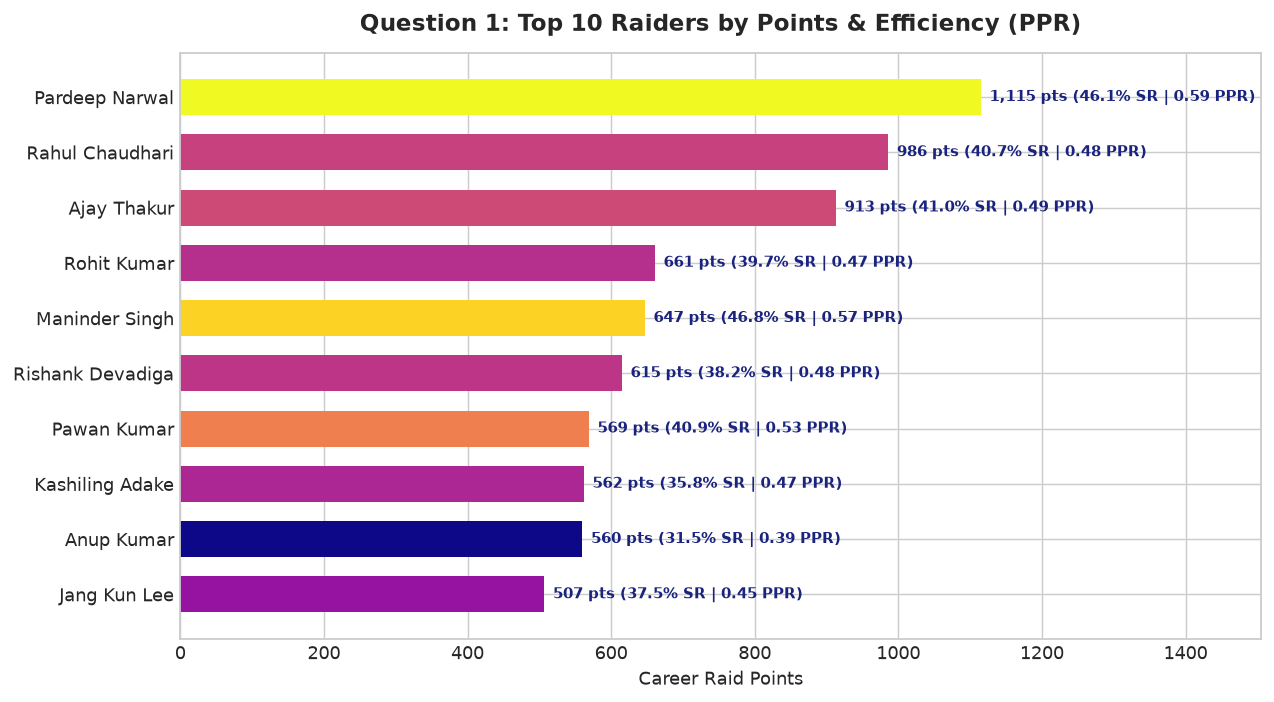

In [3]:
if df_players is not None:
    raider_agg = df_players.groupby('player_name').agg({
        'player_raid_points_total': 'sum',
        'player_raids_total': 'sum',
        'player_raids_successful': 'sum'
    }).reset_index()

    raiders_q = raider_agg[raider_agg['player_raids_total'] >= 50].copy()
    raiders_q['strike_rate'] = (raiders_q['player_raids_successful'] / raiders_q['player_raids_total']) * 100
    raiders_q['ppr'] = raiders_q['player_raid_points_total'] / raiders_q['player_raids_total']
    top10_raiders = raiders_q.sort_values(by='player_raid_points_total', ascending=True).tail(10)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    norm = plt.Normalize(top10_raiders['ppr'].min(), top10_raiders['ppr'].max())
    colors = plt.cm.plasma(norm(top10_raiders['ppr']))
    bars = ax.barh(top10_raiders['player_name'], top10_raiders['player_raid_points_total'], color=colors, height=0.65)

    for bar, (_, row) in zip(bars, top10_raiders.iterrows()):
        w = bar.get_width()
        ax.text(w + 12, bar.get_y() + bar.get_height()/2,
                f"{int(w):,} pts ({row['strike_rate']:.1f}% SR | {row['ppr']:.2f} PPR)",
                va='center', fontsize=8.5, fontweight='bold', color='#1a237e')

    ax.set_xlim(0, top10_raiders['player_raid_points_total'].max() * 1.35)
    ax.set_title("Question 1: Top 10 Raiders by Points & Efficiency (PPR)", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Career Raid Points", fontsize=10)
    plt.tight_layout()
    plt.show()


### Step 4: Graph 2 - Top 10 Defensive Fortresses & Tackle Conversion

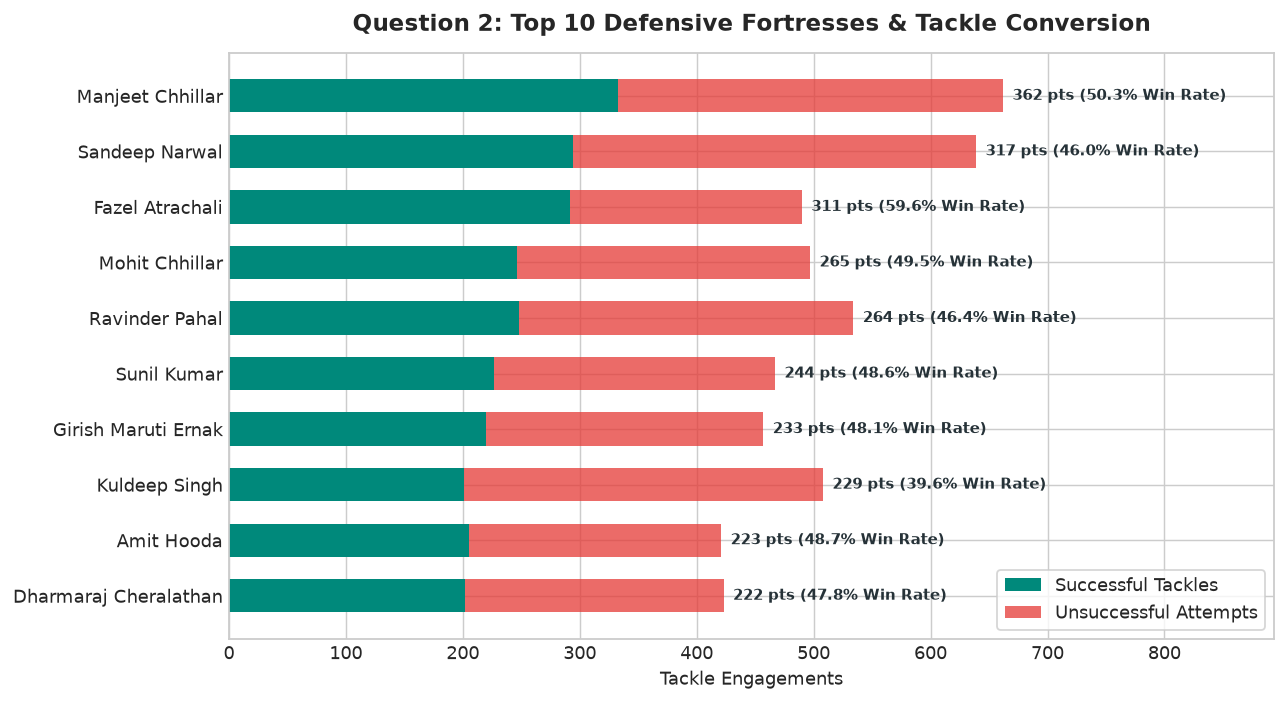

In [4]:
if df_players is not None:
    def_agg = df_players.groupby('player_name').agg({
        'player_tackle_points_total': 'sum',
        'player_tackles_total': 'sum',
        'player_tackles_successful': 'sum',
        'player_tackles_unsuccessful': 'sum'
    }).reset_index()

    def_q = def_agg[def_agg['player_tackles_total'] >= 30].copy()
    def_q['conversion'] = (def_q['player_tackles_successful'] / def_q['player_tackles_total']) * 100
    top10_def = def_q.sort_values(by='player_tackle_points_total', ascending=True).tail(10)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.barh(top10_def['player_name'], top10_def['player_tackles_successful'],
            color='#00897b', label='Successful Tackles', height=0.6)
    ax.barh(top10_def['player_name'], top10_def['player_tackles_unsuccessful'],
            left=top10_def['player_tackles_successful'], color='#e53935', alpha=0.75,
            label='Unsuccessful Attempts', height=0.6)

    for _, row in top10_def.iterrows():
        tot = row['player_tackles_total']
        ax.text(tot + 8, row['player_name'],
                f"{int(row['player_tackle_points_total'])} pts ({row['conversion']:.1f}% Win Rate)",
                va='center', fontsize=8.5, fontweight='bold', color='#263238')

    ax.set_xlim(0, top10_def['player_tackles_total'].max() * 1.35)
    ax.set_title("Question 2: Top 10 Defensive Fortresses & Tackle Conversion", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Tackle Engagements", fontsize=10)
    ax.legend(loc='lower right', frameon=True)
    plt.tight_layout()
    plt.show()


### Step 5: Graph 3 - Tactical Matrix: Raid Power vs. Defensive Wall

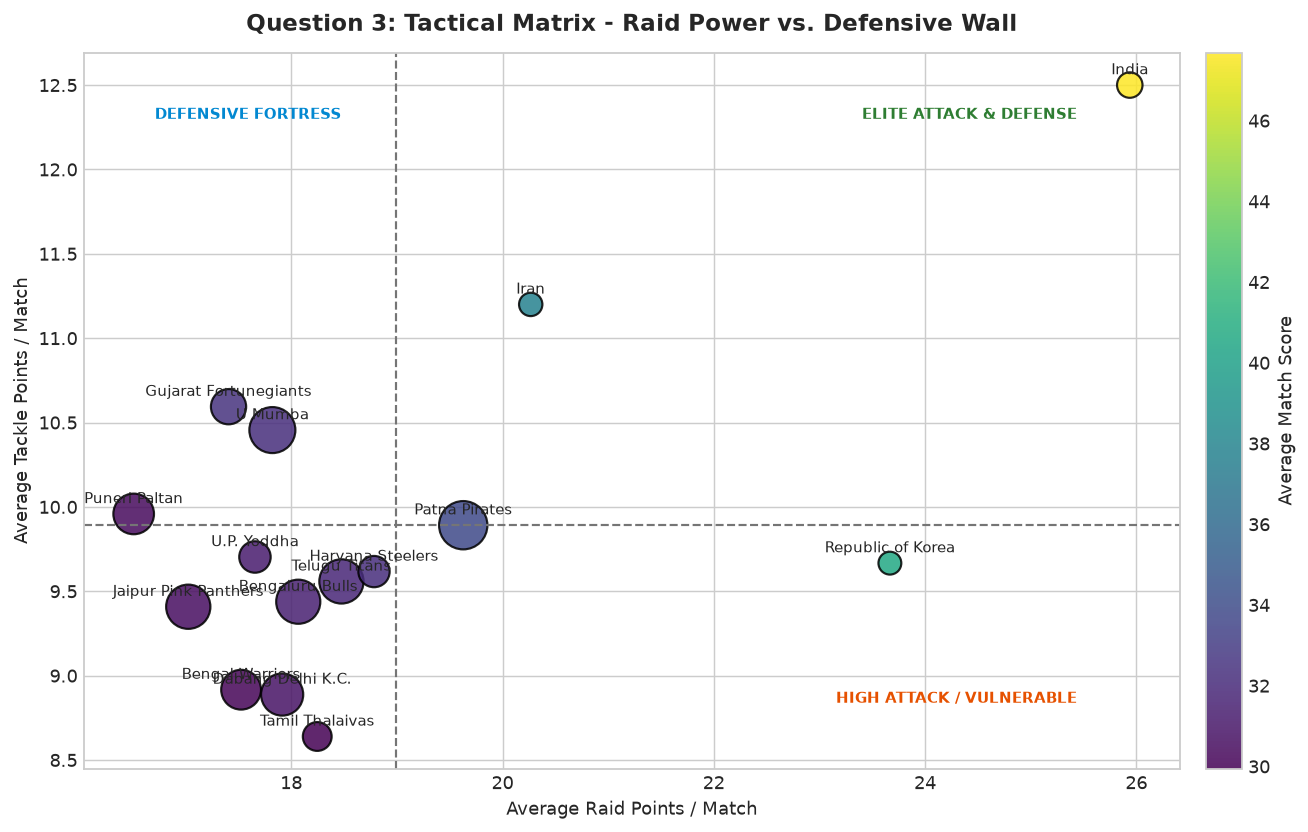

In [5]:
if df_teams is not None:
    team_perf = df_teams.groupby('team_name').agg({
        'score': 'mean',
        'raid_points_total': 'mean',
        'tackle_points_total': 'mean',
        'all_outs_inflicted': 'sum',
        'match_id': 'count'
    }).reset_index().rename(columns={'match_id': 'matches_played'})

    team_perf = team_perf[team_perf['matches_played'] >= 10].sort_values(by='score', ascending=True)

    fig, ax = plt.subplots(figsize=(11, 6.5))
    mean_raid = team_perf['raid_points_total'].mean()
    mean_tackle = team_perf['tackle_points_total'].mean()

    ax.axvline(mean_raid, color='#757575', linestyle='--', linewidth=1.2)
    ax.axhline(mean_tackle, color='#757575', linestyle='--', linewidth=1.2)

    ax.text(team_perf['raid_points_total'].max() - 0.5, team_perf['tackle_points_total'].max() - 0.2,
            'ELITE ATTACK & DEFENSE', color='#2e7d32', fontsize=8.5, fontweight='bold', ha='right')
    ax.text(team_perf['raid_points_total'].min() + 0.2, team_perf['tackle_points_total'].max() - 0.2,
            'DEFENSIVE FORTRESS', color='#0288d1', fontsize=8.5, fontweight='bold', ha='left')
    ax.text(team_perf['raid_points_total'].max() - 0.5, team_perf['tackle_points_total'].min() + 0.2,
            'HIGH ATTACK / VULNERABLE', color='#e65100', fontsize=8.5, fontweight='bold', ha='right')

    scatter = ax.scatter(
        team_perf['raid_points_total'],
        team_perf['tackle_points_total'],
        s=team_perf['all_outs_inflicted'] * 3.5 + 80,
        c=team_perf['score'],
        cmap='viridis',
        edgecolors='#000000',
        linewidth=1.2,
        alpha=0.85
    )

    for _, row in team_perf.iterrows():
        ax.annotate(row['team_name'], (row['raid_points_total'], row['tackle_points_total']),
                    xytext=(0, 6), textcoords="offset points", fontsize=8.5, ha='center')

    cbar = fig.colorbar(scatter, ax=ax, pad=0.02)
    cbar.set_label('Average Match Score', fontsize=10)

    ax.set_title("Question 3: Tactical Matrix - Raid Power vs. Defensive Wall", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Average Raid Points / Match", fontsize=10)
    ax.set_ylabel("Average Tackle Points / Match", fontsize=10)
    plt.tight_layout()
    plt.show()


### Step 6: Graph 4 - Franchise Scoring Rankings

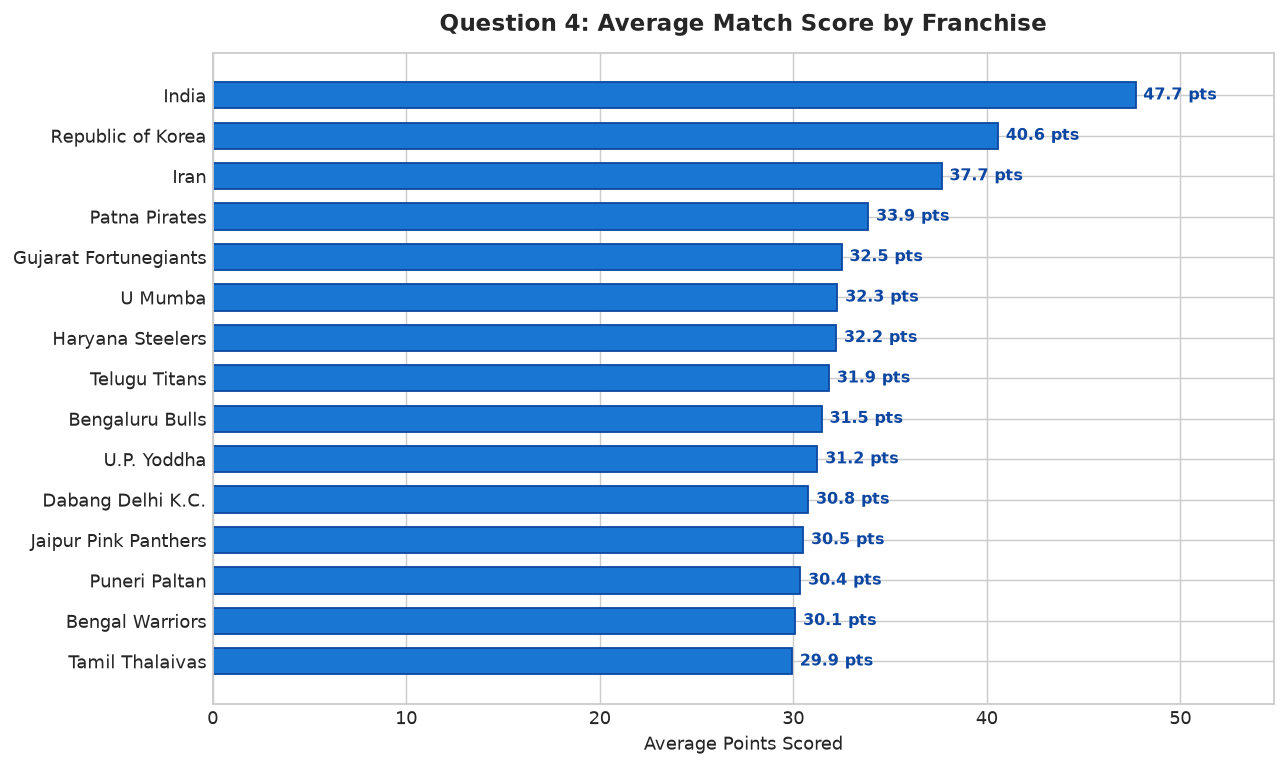

In [6]:
if df_teams is not None:
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(team_perf['team_name'], team_perf['score'], color='#1976d2', edgecolor='#0d47a1', height=0.65)

    for bar in bars:
        w = bar.get_width()
        ax.text(w + 0.4, bar.get_y() + bar.get_height()/2, f"{w:.1f} pts",
                va='center', fontsize=9, fontweight='bold', color='#0d47a1')

    ax.set_xlim(0, team_perf['score'].max() * 1.15)
    ax.set_title("Question 4: Average Match Score by Franchise", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Average Points Scored", fontsize=10)
    plt.tight_layout()
    plt.show()


### Step 7: Graph 5 - Touch Points vs. Bonus Line Crossings

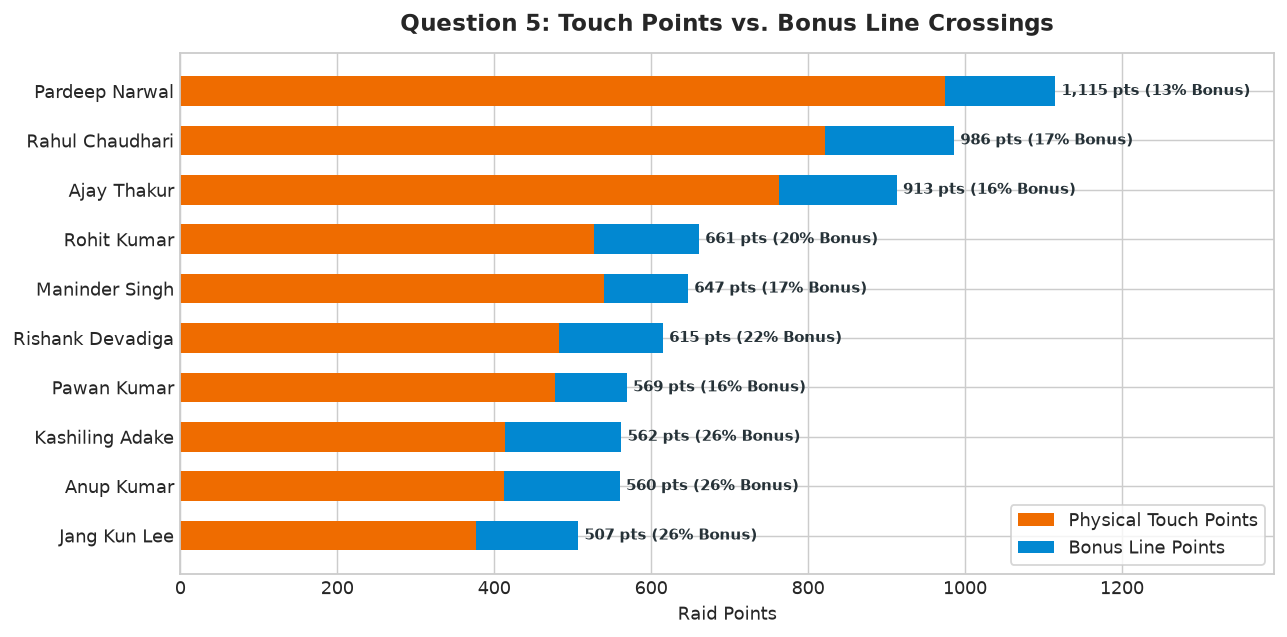

In [7]:
if df_players is not None:
    touch_bonus = df_players.groupby('player_name').agg({
        'player_raid_points_touch': 'sum',
        'player_raid_points_raid_bonus': 'sum',
        'player_raid_points_total': 'sum'
    }).reset_index().sort_values(by='player_raid_points_total', ascending=True).tail(10)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(touch_bonus['player_name'], touch_bonus['player_raid_points_touch'],
            color='#ef6c00', label='Physical Touch Points', height=0.6)
    ax.barh(touch_bonus['player_name'], touch_bonus['player_raid_points_raid_bonus'],
            left=touch_bonus['player_raid_points_touch'], color='#0288d1',
            label='Bonus Line Points', height=0.6)

    for _, row in touch_bonus.iterrows():
        tot = row['player_raid_points_total']
        pct_bonus = (row['player_raid_points_raid_bonus'] / tot * 100) if tot else 0
        ax.text(tot + 8, row['player_name'], f"{int(tot):,} pts ({pct_bonus:.0f}% Bonus)",
                va='center', fontsize=8.5, fontweight='bold', color='#263238')

    ax.set_xlim(0, touch_bonus['player_raid_points_total'].max() * 1.25)
    ax.set_title("Question 5: Touch Points vs. Bonus Line Crossings", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Raid Points", fontsize=10)
    ax.legend(loc='lower right', frameon=True)
    plt.tight_layout()
    plt.show()


### Step 8: Graph 6 - Team Final Score Escalation by All-Outs

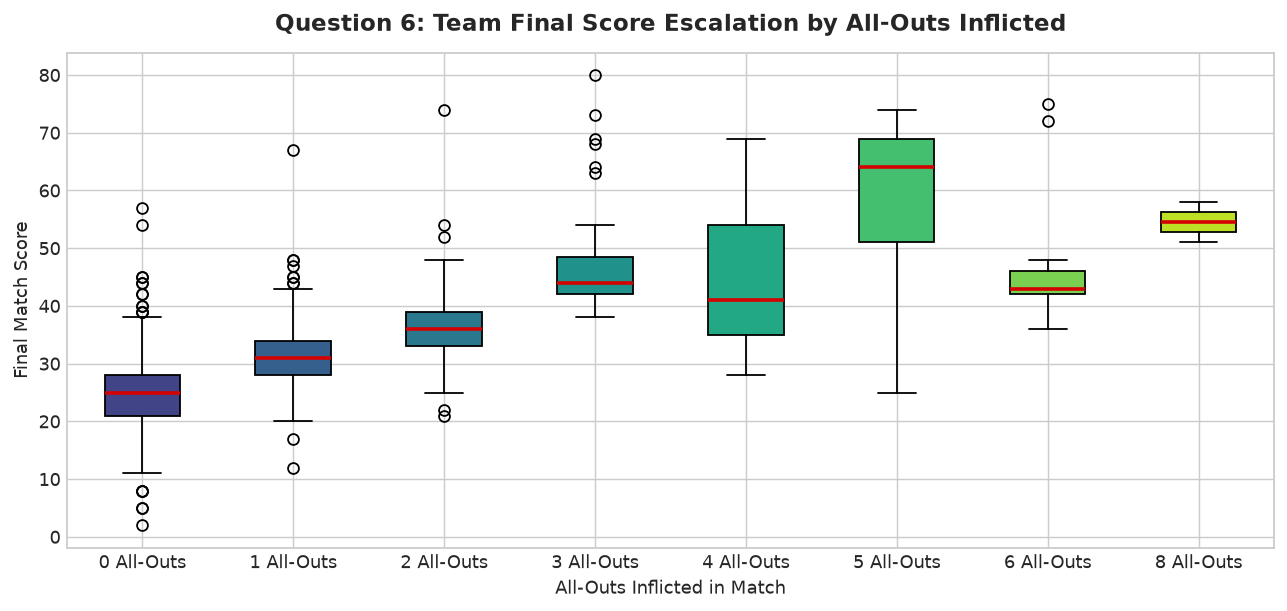

In [8]:
if df_teams is not None:
    fig, ax = plt.subplots(figsize=(10, 4.8))
    allouts = sorted(df_teams['all_outs_inflicted'].unique())
    data_by_allout = [df_teams[df_teams['all_outs_inflicted'] == a]['score'] for a in allouts]

    box = ax.boxplot(data_by_allout, tick_labels=[f"{a} All-Outs" for a in allouts],
                     patch_artist=True, medianprops=dict(color='#d50000', linewidth=2))

    palette = plt.cm.viridis(np.linspace(0.2, 0.9, len(allouts)))
    for patch, color in zip(box['boxes'], palette):
        patch.set_facecolor(color)
        patch.set_edgecolor('#000000')

    ax.set_title("Question 6: Team Final Score Escalation by All-Outs Inflicted", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("All-Outs Inflicted in Match", fontsize=10)
    ax.set_ylabel("Final Match Score", fontsize=10)
    plt.tight_layout()
    plt.show()


### Step 9: Graph 7 - Victory Margin Distribution (Clutch Games)

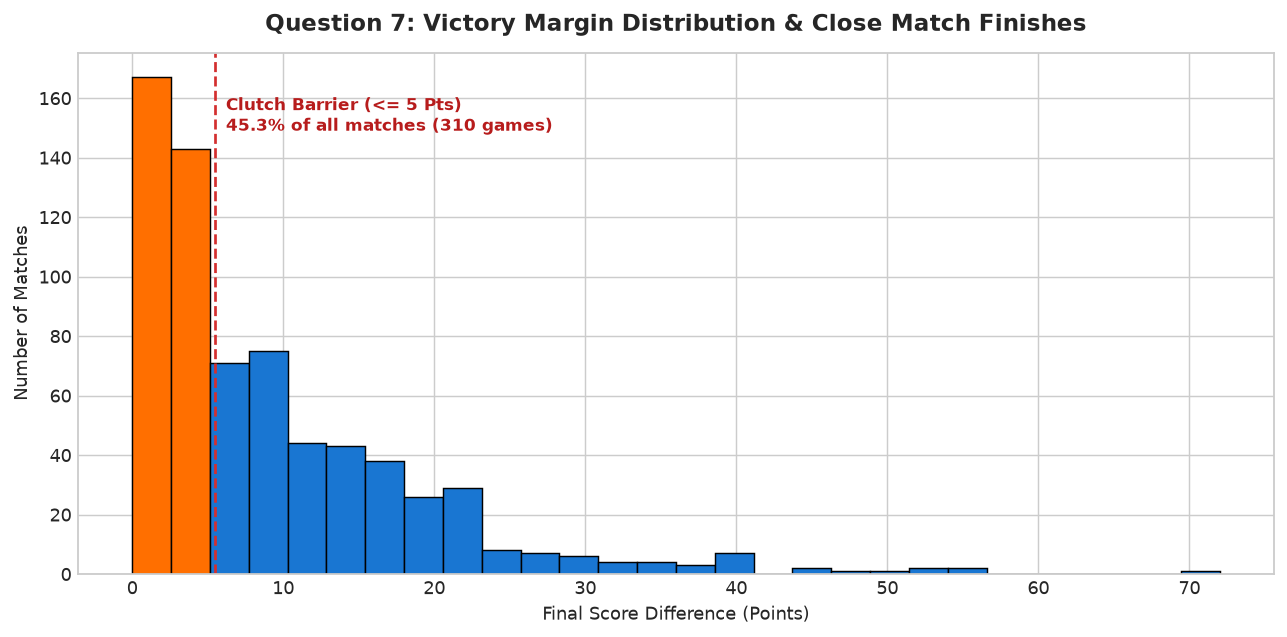

In [9]:
if df_teams is not None:
    team_margins = df_teams.groupby('match_id')['score'].agg(
        lambda s: abs(s.iloc[0] - s.iloc[1]) if len(s) == 2 else 0
    ).reset_index().rename(columns={'score': 'margin'})

    close_count = (team_margins['margin'] <= 5).sum()
    close_pct = (close_count / len(team_margins)) * 100

    fig, ax = plt.subplots(figsize=(10, 5))
    n, bins, patches_list = ax.hist(team_margins['margin'], bins=28, edgecolor='black', linewidth=0.8)
    for patch, b in zip(patches_list, bins):
        patch.set_facecolor('#ff6f00' if b <= 5 else '#1976d2')

    ax.axvline(5.5, color='#d32f2f', linestyle='--', linewidth=1.5)
    ax.text(6.2, ax.get_ylim()[1] * 0.85, f"Clutch Barrier (<= 5 Pts)\n{close_pct:.1f}% of all matches ({close_count} games)",
            color='#b71c1c', fontsize=9.5, fontweight='bold')

    ax.set_title("Question 7: Victory Margin Distribution & Close Match Finishes", fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel("Final Score Difference (Points)", fontsize=10)
    ax.set_ylabel("Number of Matches", fontsize=10)
    plt.tight_layout()
    plt.show()


### Step 10: Graph 8 - Toss Decision Preference

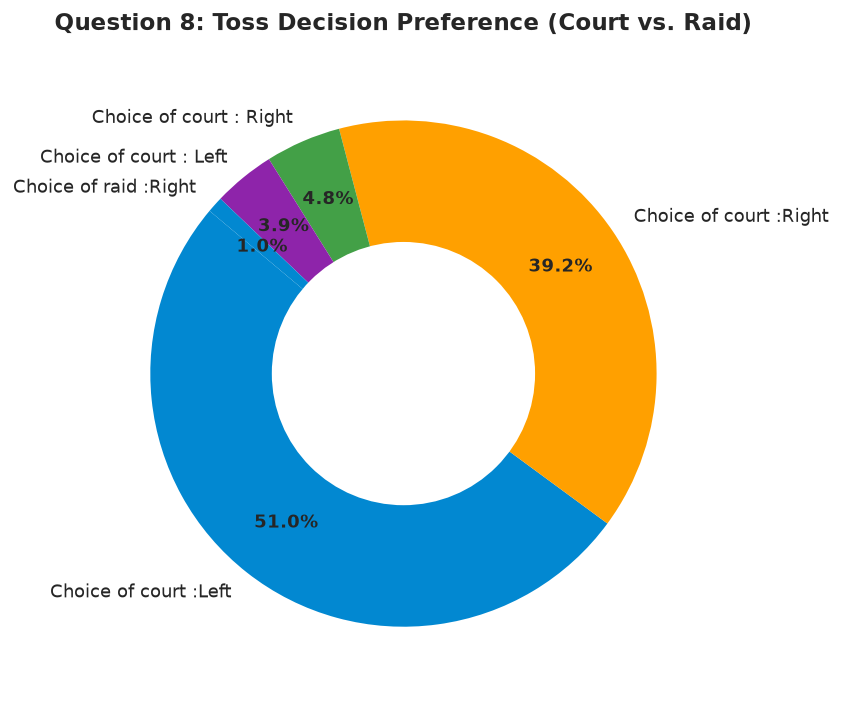

In [10]:
if df_matches is not None and 'toss_selection' in df_matches.columns:
    toss_counts = df_matches['toss_selection'].value_counts()

    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    wedges, texts, autotexts = ax.pie(
        toss_counts.values,
        labels=toss_counts.index,
        autopct='%1.1f%%',
        startangle=140,
        pctdistance=0.75,
        colors=['#0288d1', '#ffa000', '#43a047', '#8e24aa']
    )

    centre_circle = plt.Circle((0, 0), 0.52, fc='white')
    ax.add_artist(centre_circle)

    for at in autotexts:
        at.set_fontsize(10)
        at.set_fontweight('bold')

    ax.set_title("Question 8: Toss Decision Preference (Court vs. Raid)", fontsize=13, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.show()
